# A3 · Detección de Fugas de Ingresos
**Proyecto 01 — Retail Intelligence (RetailVenture C.A.)**

Preguntas del enunciado:
1. **Devoluciones**: ¿hay productos, categorías o segmentos con tasas anómalas? ¿Hay clientes recurrentes en devoluciones?
2. **CRM → compras**: ¿los clientes con quejas no resueltas disminuyeron su frecuencia de compra?
3. **Churn**: definir una métrica de inactividad e identificar el segmento de mayor valor en riesgo.
4. **Impacto económico** de las fugas, proyectado a **6 meses**.

Principio metodológico: toda diferencia se contrasta contra **lo que se esperaría por azar** (pruebas binomiales con corrección por comparaciones múltiples) o contra un **grupo de control**, para no presentar como causa algo que es correlación o ruido.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy import stats
from pathlib import Path

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)
CLEAN, FIG, TAB = Path('../data/clean'), Path('../outputs/figuras'), Path('../outputs/tablas')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'text.parse_math': False})
ORDEN_SEG = ['Premium', 'Frecuente', 'Esporádico', 'Nuevo', 'Inactivo']
PALETA = {'Premium': '#2E4057', 'Frecuente': '#4C72B0', 'Esporádico': '#8DA0CB', 'Nuevo': '#55A868', 'Inactivo': '#C44E52'}
INI, CORTE = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-12-31')

ventas = pd.read_csv(CLEAN / 'fact_ventas.csv', parse_dates=['fecha'])
clientes = pd.read_csv(CLEAN / 'dim_cliente.csv', parse_dates=['fecha_registro', 'primera_compra', 'ultima_compra', 'fecha_alta_efectiva'])
devol = pd.read_csv(CLEAN / 'fact_devoluciones.csv', parse_dates=['fecha_devolucion', 'fecha_compra'])
crm = pd.read_csv(CLEAN / 'fact_interacciones.csv', parse_dates=['fecha'])
seg = clientes.set_index('cliente_id').segmento
ventas['segmento'] = ventas.cliente_id.map(seg)
P0 = ventas.flag_devuelta.mean()
print(f'Tasa global de devolución: {P0:.2%} ({ventas.flag_devuelta.sum():,} de {len(ventas):,} transacciones)')
print(f'Monto devuelto: ${ventas.monto_devuelto.sum():,.0f} ({ventas.monto_devuelto.sum() / ventas.monto_neto.sum():.1%} de las ventas)')
print(f'Margen perdido por devoluciones (bruto − neto): ${(ventas.margen_bruto - ventas.margen_neto).sum():,.0f}')

Tasa global de devolución: 13.45% (6,724 de 50,000 transacciones)
Monto devuelto: $2,534,466 (14.6% de las ventas)
Margen perdido por devoluciones (bruto − neto): $1,187,099


## 1. Patrón de devoluciones

### 1.1 Tasas por dimensión y prueba de independencia (χ²)

In [2]:
filas = []
for dim in ['categoria', 'subcategoria', 'canal', 'segmento', 'metodo_pago']:
    tab = pd.crosstab(ventas[dim], ventas.flag_devuelta)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    v_cramer = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    r = ventas.groupby(dim).flag_devuelta.mean()
    filas.append({'dimensión': dim, 'chi2': chi2, 'p_valor': p, 'V_Cramer': v_cramer,
                  'tasa_min': f'{r.min():.1%} ({r.idxmin()})', 'tasa_max': f'{r.max():.1%} ({r.idxmax()})'})
pruebas = pd.DataFrame(filas).set_index('dimensión'); pruebas.to_csv(TAB / 'a3_devoluciones_chi2.csv')
display(pruebas.style.format({'chi2': '{:,.1f}', 'p_valor': '{:.2e}', 'V_Cramer': '{:.3f}'}))

dc = ventas.groupby('categoria').agg(transacciones=('transaccion_id', 'size'), devoluciones=('flag_devuelta', 'sum'), tasa=('flag_devuelta', 'mean'),
                                     ventas=('monto_neto', 'sum'), devuelto=('monto_devuelto', 'sum'),
                                     margen_perdido=('margen_bruto', 'sum')).sort_values('tasa', ascending=False)
dc['margen_perdido'] = (ventas.groupby('categoria').margen_bruto.sum() - ventas.groupby('categoria').margen_neto.sum())
dc['%_del_devuelto_total'] = dc.devuelto / dc.devuelto.sum() * 100
dc.to_csv(TAB / 'a3_devoluciones_categoria.csv')
dc.style.format({'tasa': '{:.1%}', 'ventas': '${:,.0f}', 'devuelto': '${:,.0f}', 'margen_perdido': '${:,.0f}', '%_del_devuelto_total': '{:.1f}%'})

,chi2,p_valor,V_Cramer,tasa_min,tasa_max
dimensión,,,,,
categoria,909.5,2.36e-194,0.135,9.8% (Hogar_y_Deco),21.8% (Ropa_y_Calzado)
subcategoria,935.9,5.51e-183,0.137,8.8% (Decoración),22.9% (Accesorios_moda)
canal,2.5,2.87e-01,0.007,13.2% (tienda_fisica),13.8% (online)
segmento,2.6,6.34e-01,0.007,12.1% (Nuevo),13.7% (Esporádico)
metodo_pago,0.8,9.42e-01,0.004,13.1% (transferencia),13.6% (billetera_digital)


,transacciones,devoluciones,tasa,ventas,devuelto,margen_perdido,%_del_devuelto_total
categoria,,,,,,,
Ropa_y_Calzado,8311,1810,21.8%,"$1,513,397","$320,972","$186,482",12.7%
Electrónica,8419,1486,17.7%,"$7,662,506","$1,398,217","$562,833",55.2%
Deportes,8311,887,10.7%,"$2,592,709","$271,615","$150,042",10.7%
Belleza_y_Salud,8287,878,10.6%,"$748,632","$79,805","$48,417",3.1%
Alimentos_y_Bebidas,8317,845,10.2%,"$409,879","$42,910","$20,843",1.7%
Hogar_y_Deco,8355,818,9.8%,"$4,465,865","$420,948","$218,481",16.6%


In [3]:
# Segmento × categoría: ¿el segmento importa una vez que se controla la categoría?
display((pd.crosstab(ventas.segmento, ventas.categoria, values=ventas.flag_devuelta, aggfunc='mean') * 100).loc[ORDEN_SEG].round(1))
lg = smf.logit('flag_devuelta ~ C(categoria) + C(segmento, Treatment("Premium")) + C(canal) + descuento', data=ventas).fit(disp=0)
or_ = pd.DataFrame({'odds_ratio': np.exp(lg.params), 'p_valor': lg.pvalues}).drop('Intercept')
or_.index = or_.index.str.replace(r'C\((\w+).*?\)\[T\.', r'\1=', regex=True).str.rstrip(']')
display(or_.round(3))

categoria,Alimentos_y_Bebidas,Belleza_y_Salud,Deportes,Electrónica,Hogar_y_Deco,Ropa_y_Calzado
segmento,,,,,,
Premium,10.6,11.4,11.3,16.4,9.3,21.5
Frecuente,10.0,10.2,10.4,18.1,9.8,22.3
Esporádico,10.0,10.8,10.4,19.0,10.5,21.5
Nuevo,11.5,9.7,11.2,14.1,9.6,16.4
Inactivo,7.6,5.7,10.8,17.9,12.3,20.5


,odds_ratio,p_valor
categoria=Belleza_y_Salud,1.048,0.361
categoria=Deportes,1.056,0.288
categoria=Electrónica,1.894,0.000
categoria=Hogar_y_Deco,0.959,0.422
categoria=Ropa_y_Calzado,2.463,0.000
segmento=Esporádico,1.023,0.585
segmento=Frecuente,1.003,0.918
segmento=Inactivo,0.926,0.464
segmento=Nuevo,0.883,0.227
canal=online,1.031,0.443


### 1.2 ¿Productos anómalos? Prueba binomial por producto con corrección FDR (Benjamini-Hochberg)

In [4]:
pr = ventas.groupby('producto_id').agg(n=('flag_devuelta', 'size'), k=('flag_devuelta', 'sum'), categoria=('categoria', 'first'),
                                       subcategoria=('subcategoria', 'first'), devuelto=('monto_devuelto', 'sum'))
pr['tasa'] = pr.k / pr.n
tasa_cat = ventas.groupby('categoria').flag_devuelta.mean()
pr['p_vs_global'] = [stats.binomtest(int(k), int(n), P0, alternative='greater').pvalue for k, n in zip(pr.k, pr.n)]
pr['p_vs_categoria'] = [stats.binomtest(int(k), int(n), tasa_cat[c], alternative='greater').pvalue for k, n, c in zip(pr.k, pr.n, pr.categoria)]
pr['q_vs_global'] = multipletests(pr.p_vs_global, method='fdr_bh')[1]
pr['q_vs_categoria'] = multipletests(pr.p_vs_categoria, method='fdr_bh')[1]
pr.to_csv(TAB / 'a3_devoluciones_producto.csv')
print(f"Productos con tasa anómala vs. el promedio GLOBAL (q < 0,05): {(pr.q_vs_global < .05).sum()}")
print(pr[pr.q_vs_global < .05].categoria.value_counts().to_dict())
print(f"Productos con tasa anómala vs. el promedio de SU CATEGORÍA (q < 0,05): {(pr.q_vs_categoria < .05).sum()}")
print('\nTop 10 productos por tasa de devolución:')
display(pr.sort_values('tasa', ascending=False).head(10)[['categoria', 'subcategoria', 'n', 'k', 'tasa', 'q_vs_global', 'q_vs_categoria']].round(3))

Productos con tasa anómala vs. el promedio GLOBAL (q < 0,05): 39
{'Ropa_y_Calzado': 32, 'Electrónica': 7}
Productos con tasa anómala vs. el promedio de SU CATEGORÍA (q < 0,05): 0

Top 10 productos por tasa de devolución:


,categoria,subcategoria,n,k,tasa,q_vs_global,q_vs_categoria
producto_id,,,,,,,
PRD0095,Ropa_y_Calzado,Accesorios_moda,157,50,0.318,0.000,0.706
PRD0080,Ropa_y_Calzado,Accesorios_moda,158,41,0.259,0.002,0.993
PRD0083,Ropa_y_Calzado,Ropa_masculina,162,42,0.259,0.002,0.993
PRD0093,Ropa_y_Calzado,Ropa_femenina,146,37,0.253,0.004,0.993
PRD0065,Ropa_y_Calzado,Ropa_femenina,150,38,0.253,0.004,0.993
PRD0072,Ropa_y_Calzado,Ropa_femenina,190,48,0.253,0.002,0.993
PRD0057,Ropa_y_Calzado,Ropa_masculina,157,39,0.248,0.004,0.993
PRD0082,Ropa_y_Calzado,Ropa_femenina,159,39,0.245,0.005,0.993
PRD0087,Ropa_y_Calzado,Ropa_masculina,143,35,0.245,0.007,0.993


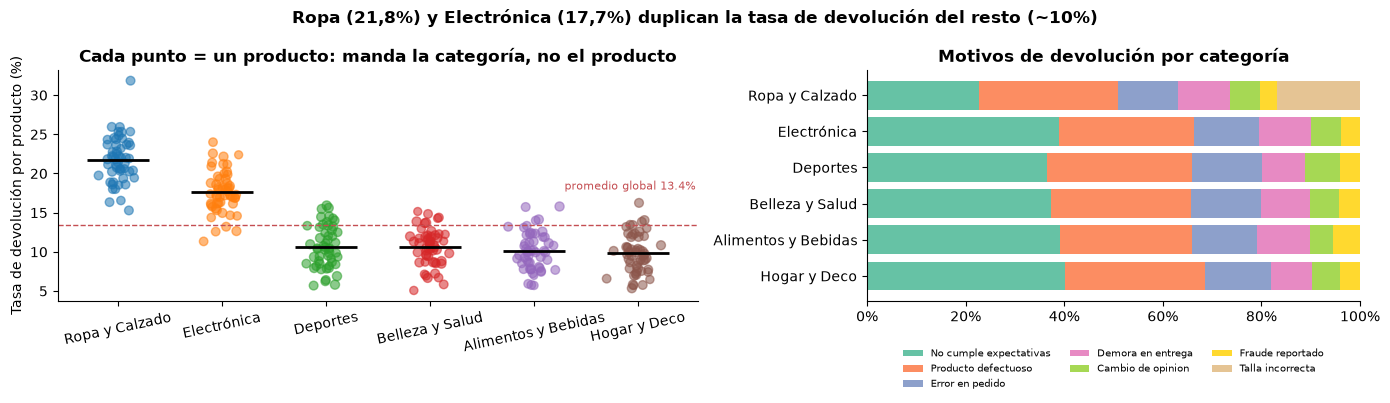

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]; cats = dc.index.tolist(); rng = np.random.default_rng(0)
for k, c_ in enumerate(cats):
    s = pr[pr.categoria == c_]
    ax.scatter(rng.normal(k, .08, len(s)), s.tasa * 100, s=s.n / 4, alpha=.55, color=plt.cm.tab10(k))
    ax.hlines(tasa_cat[c_] * 100, k - .3, k + .3, color='k', lw=2)
ax.axhline(P0 * 100, color='#C44E52', ls='--', lw=1); ax.text(len(cats) - .45, P0 * 100 + 4.5, f'promedio global {P0:.1%}', color='#C44E52', ha='right', fontsize=8)
ax.set_xticks(range(len(cats)), [c_.replace('_', ' ') for c_ in cats], rotation=12); ax.set_ylabel('Tasa de devolución por producto (%)')
ax.set_title('Cada punto = un producto: manda la categoría, no el producto')
ax = axes[1]
mot = pd.crosstab(devol.categoria, devol.motivo, normalize='index').loc[cats] * 100
mot = mot[mot.mean().sort_values(ascending=False).index]
left = np.zeros(len(mot))
for k, m_ in enumerate(mot.columns):
    ax.barh(range(len(mot)), mot[m_], left=left, label=m_.replace('_', ' '), color=plt.cm.Set2(k)); left += mot[m_].values
ax.set_yticks(range(len(mot)), [c_.replace('_', ' ') for c_ in mot.index]); ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(fontsize=7, frameon=False, loc='lower center', bbox_to_anchor=(.5, -.42), ncol=3); ax.set_title('Motivos de devolución por categoría')
plt.suptitle('Ropa (21,8%) y Electrónica (17,7%) duplican la tasa de devolución del resto (~10%)', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a3_devoluciones_categoria.png', dpi=150, bbox_inches='tight'); plt.show()

In [6]:
# Tendencia temporal de la tasa de devolución (¿"aumentó al 14%"?)
q = ventas.groupby(ventas.fecha.dt.to_period('Q')).flag_devuelta.agg(['mean', 'size'])
q['IC95'] = 1.96 * np.sqrt(q['mean'] * (1 - q['mean']) / q['size'])
display((q[['mean', 'IC95']] * 100).round(2))
tab = pd.crosstab(ventas.fecha.dt.to_period('Q'), ventas.flag_devuelta)
print('χ² homogeneidad entre trimestres: p =', round(stats.chi2_contingency(tab)[1], 3))
print('Tendencia (logit sobre n.º de mes): ', end='')
lt = smf.logit('flag_devuelta ~ t', data=ventas.assign(t=(ventas.fecha.dt.year - 2023) * 12 + ventas.fecha.dt.month)).fit(disp=0)
print(f"OR por mes = {np.exp(lt.params['t']):.4f}, p = {lt.pvalues['t']:.3f}")

,mean,IC95
fecha,,
2023Q1,13.22,0.85
2023Q2,13.65,0.85
2023Q3,12.97,0.84
2023Q4,13.84,0.85
2024Q1,13.31,0.84
2024Q2,13.32,0.84
2024Q3,13.81,0.86
2024Q4,13.45,0.84


χ² homogeneidad entre trimestres: p = 0.846
Tendencia (logit sobre n.º de mes): OR por mes = 1.0007, p = 0.727


**Lectura: la tasa de devolución la determina la categoría y nada más.**

- La **categoría** (y la subcategoría) es la única dimensión con una asociación significativa (χ², p ≈ 10⁻¹⁹⁴; V de Cramér = 0,14). **Canal, segmento y método de pago no influyen** (p = 0,29, 0,63 y 0,94).
- La regresión logística lo confirma controlando todo a la vez. Ropa y Calzado tiene **2,5 veces más probabilidad (odds)** de devolverse y Electrónica 1,9 veces, frente a Alimentos. Segmento, canal y **descuento** no son significativos: comprar con descuento no hace que se devuelva más.
- **Productos:** 39 productos tienen una tasa anómala frente al promedio global (32 de Ropa, 7 de Electrónica), pero **ninguno** frente al promedio de su propia categoría (FDR q < 0,05). No hay "productos problema" aislados: es un **problema de categoría**, y lo que hay que corregir es la propuesta de valor de la categoría completa, no un SKU puntual.
- **Electrónica** genera el 55% del monto devuelto ($1,4M) y $563K de margen perdido, el 47% del total. Sus motivos son "no cumple expectativas" (39%) y "defectuoso" (27%): problemas de **descripción del producto y de calidad del proveedor**.
- **Ropa:** el 17% de sus devoluciones son por **talla incorrecta**, un motivo que no existe en otras categorías y que se puede atacar con guías de talla.
- **Tendencia:** la tasa es estable entre 13,0% y 13,8% en los 8 trimestres (χ² p = 0,85; tendencia p = 0,73). El 14% del caso es real, pero **no es un aumento reciente**: es estructural desde 2023.

### 1.3 ¿Hay clientes recurrentes en devoluciones?

Un cliente que compra 30 veces va a acumular más devoluciones que uno que compra 2, aunque los dos devuelvan con la misma probabilidad. Por eso, contar devoluciones por cliente **no alcanza** para hablar de devolvedores seriales. Se hacen dos pruebas:
1. **Prueba binomial por cliente**: ¿su número de devoluciones es improbable dadas sus compras y la tasa de *sus* categorías? Se corrige con FDR.
2. **Simulación**: se generan 500 carteras ficticias en las que todos los clientes devuelven con la misma probabilidad (la de cada categoría) y se compara la distribución observada con la esperada.

In [7]:
ventas['p_esperada'] = ventas.categoria.map(tasa_cat)
cu = ventas.groupby('cliente_id').agg(compras=('flag_devuelta', 'size'), devoluciones=('flag_devuelta', 'sum'), p_esp=('p_esperada', 'mean'),
                                      margen_neto=('margen_neto', 'sum'), devuelto=('monto_devuelto', 'sum'))
cu['segmento'] = seg
cu['p_valor'] = stats.binom.sf(cu.devoluciones - 1, cu.compras, cu.p_esp)
cu['q_valor'] = multipletests(cu.p_valor, method='fdr_bh')[1]
print(f"Clientes con ≥ 1 devolución: {(cu.devoluciones > 0).sum():,} ({(cu.devoluciones > 0).mean():.1%})")
print(f"Clientes con devoluciones anómalas (FDR q < 0,05): {(cu.q_valor < .05).sum()}")
print(f"Clientes con p < 0,01 sin corregir: {(cu.p_valor < .01).sum()} (se esperarían ~{len(cu) * .01:.0f} por azar)")

rng = np.random.default_rng(42)
# simulación a nivel transacción (respeta la categoría de cada compra)
sims = np.array([ventas.assign(s=rng.random(len(ventas)) < ventas.p_esperada).groupby('cliente_id').s.sum().values for _ in range(500)])
comp = pd.DataFrame({'umbral': [f'≥{k} devoluciones' for k in range(2, 9)],
                     'observado': [(cu.devoluciones >= k).sum() for k in range(2, 9)],
                     'esperado_por_azar': [(sims >= k).sum(1).mean() for k in range(2, 9)],
                     'IC95_azar': [f"{np.percentile((sims >= k).sum(1), 2.5):.0f}–{np.percentile((sims >= k).sum(1), 97.5):.0f}" for k in range(2, 9)]})
comp.to_csv(TAB / 'a3_devolvedores_vs_azar.csv', index=False)
comp

Clientes con ≥ 1 devolución: 3,679 (48.4%)
Clientes con devoluciones anómalas (FDR q < 0,05): 0
Clientes con p < 0,01 sin corregir: 14 (se esperarían ~76 por azar)


,umbral,observado,esperado_por_azar,IC95_azar
0,≥2 devoluciones,1711,1709.506,1654–1764
1,≥3 devoluciones,793,785.666,743–834
2,≥4 devoluciones,348,327.054,297–356
3,≥5 devoluciones,120,123.276,104–143
4,≥6 devoluciones,44,42.472,30–55
5,≥7 devoluciones,20,13.542,7–21
6,≥8 devoluciones,7,3.924,1–8


In [8]:
# Fraude reportado: ¿se concentra en pocos clientes?
fr = devol[devol.motivo == 'Fraude_reportado']
print(f"Devoluciones por fraude: {len(fr)} (${fr.monto_devuelto.sum():,.0f}) en {fr.cliente_id.nunique()} clientes; "
      f"clientes con más de un fraude: {(fr.cliente_id.value_counts() > 1).sum()}")
print('Fraude por canal (% de las devoluciones del canal):', (pd.crosstab(devol.canal, devol.motivo == 'Fraude_reportado', normalize='index')[True] * 100).round(1).to_dict())
# Concentración del monto devuelto
cd_ = cu.devuelto.sort_values(ascending=False); top = cd_.iloc[:int(len(cd_) * .05)].sum() / cd_.sum()
print(f"El 5% de clientes con mayor monto devuelto concentra el {top:.1%} del monto (explicado por el valor de lo que compran, ver correlación):")
print(f"  correlación monto devuelto vs. monto comprado por cliente: r = {np.corrcoef(cu.devuelto, ventas.groupby('cliente_id').monto_neto.sum().reindex(cu.index))[0, 1]:.2f}")

Devoluciones por fraude: 272 ($86,410) en 265 clientes; clientes con más de un fraude: 5
Fraude por canal (% de las devoluciones del canal): {'app_movil': 4.2, 'online': 3.5, 'tienda_fisica': 4.5}
El 5% de clientes con mayor monto devuelto concentra el 40.9% del monto (explicado por el valor de lo que compran, ver correlación):
  correlación monto devuelto vs. monto comprado por cliente: r = 0.55


**Lectura: no hay devolvedores seriales.**

- El 48% de los clientes ha devuelto algo al menos una vez. Pero, una vez que se consideran sus compras y las categorías que compran, **ningún cliente tiene un número de devoluciones estadísticamente anómalo** (FDR q < 0,05). Sin corregir, solo 14 tienen p < 0,01, cuando por puro azar se esperarían ~76.
- La simulación lo confirma: la cantidad de clientes con 2, 3, 4, 5 o 6 devoluciones o más está **dentro del intervalo esperado por azar** (por ejemplo, ≥ 3 devoluciones: 793 observados vs. 786 esperados, IC 743–834). Solo en la cola extrema (≥ 7–8 devoluciones) hay un pequeño exceso de ~5 clientes, sin impacto económico.
- Que el 5% de los clientes concentre el 41% del monto devuelto se explica porque **son los que más compran** (r = 0,55 entre monto comprado y monto devuelto), no porque abusen.
- **Fraude:** 272 casos ($86K) repartidos en 265 clientes; solo 5 lo repiten. No hay redes de fraude identificables.

**Implicación:** bloquear o penalizar a los "devolvedores frecuentes" **no reduciría las devoluciones** y castigaría a los mejores clientes. La palanca está en **qué categorías se venden y cómo se describen**.

## 2. CRM: ¿las quejas no resueltas reducen la frecuencia de compra?

**Diseño (diferencias en diferencias con grupo de control):**
- **Evento**: la *primera queja* de cada cliente. Se exige que haya 180 días de historia antes y después, así que el evento debe caer entre 2023-07-01 y 2024-07-03.
- **Resultado**: compras e importe en los 180 días *posteriores* menos los 180 días *anteriores* (Δ por cliente).
- **Grupos**: queja `resuelto`, `parcialmente_resuelto`, `escalado` y `sin_resolver`.
- **Control**: clientes **sin ninguna interacción CRM**, a los que se les asigna una fecha ficticia aleatoria en la misma ventana. Su Δ mide la evolución "natural" de la compra, que incluye la regresión a la media.
- **Modelo ANCOVA**: compras_post ~ grupo + compras_pre + segmento. Controlar por compras_pre corrige la regresión a la media: un cliente que compró mucho antes del evento tiende a comprar menos después, con o sin queja.
- Robustez: ventana de 90 días.

In [9]:
tt = ventas[['cliente_id', 'fecha', 'monto_neto']]

def ventana(eventos, W):
    x = eventos[['cliente_id', 'fecha_ev']].merge(tt, on='cliente_id', how='left')
    x['dd'] = (x.fecha - x.fecha_ev).dt.days
    pre = x[(x.dd < 0) & (x.dd >= -W)].groupby('cliente_id').agg(n_pre=('monto_neto', 'size'), v_pre=('monto_neto', 'sum'))
    post = x[(x.dd > 0) & (x.dd <= W)].groupby('cliente_id').agg(n_post=('monto_neto', 'size'), v_post=('monto_neto', 'sum'))
    out = eventos.set_index('cliente_id').join(pre).join(post).fillna({'n_pre': 0, 'n_post': 0, 'v_pre': 0, 'v_post': 0})
    out['d_n'] = out.n_post - out.n_pre; out['d_v'] = out.v_post - out.v_pre; out['sin_compra_post'] = (out.n_post == 0).astype(int)
    out['segmento'] = out.index.map(seg)
    return out

def construir(W):
    q = crm[crm.tipo == 'queja'].sort_values('fecha').groupby('cliente_id').first().reset_index().rename(columns={'fecha': 'fecha_ev'})
    q = q[(q.fecha_ev - pd.Timedelta(days=W) >= INI) & (q.fecha_ev + pd.Timedelta(days=W) <= CORTE)]
    q['grupo'] = 'queja_' + q.resolucion
    rng = np.random.default_rng(7)
    ctrl = clientes[~clientes.cliente_id.isin(crm.cliente_id) & clientes.primera_compra.notna()][['cliente_id']].copy()
    lo, hi = (INI + pd.Timedelta(days=W)).value // 10**9, (CORTE - pd.Timedelta(days=W)).value // 10**9
    ctrl['fecha_ev'] = pd.to_datetime(rng.integers(lo, hi, len(ctrl)), unit='s').normalize(); ctrl['grupo'] = 'control_sin_CRM'
    return pd.concat([ventana(q[['cliente_id', 'fecha_ev', 'grupo', 'tiempo_respuesta_wins']], W), ventana(ctrl, W)])

ev = construir(180)
ORDEN_G = ['control_sin_CRM', 'queja_resuelto', 'queja_parcialmente_resuelto', 'queja_escalado', 'queja_sin_resolver']
resumen = ev.groupby('grupo').agg(clientes=('d_n', 'size'), compras_pre=('n_pre', 'mean'), compras_post=('n_post', 'mean'), delta_compras=('d_n', 'mean'),
                                  gasto_pre=('v_pre', 'mean'), gasto_post=('v_post', 'mean'), sin_compra_post=('sin_compra_post', 'mean')).loc[ORDEN_G]
resumen['delta_gasto_%'] = (resumen.gasto_post / resumen.gasto_pre - 1) * 100
resumen.to_csv(TAB / 'a3_crm_did_resumen.csv')
resumen.style.format({'compras_pre': '{:.2f}', 'compras_post': '{:.2f}', 'delta_compras': '{:+.2f}', 'gasto_pre': '${:,.0f}', 'gasto_post': '${:,.0f}',
                      'sin_compra_post': '{:.1%}', 'delta_gasto_%': '{:+.1f}%'})

,clientes,compras_pre,compras_post,delta_compras,gasto_pre,gasto_post,sin_compra_post,delta_gasto_%
grupo,,,,,,,,
control_sin_CRM,5332,1.61,1.66,+0.05,$551,$585,34.9%,+6.1%
queja_resuelto,272,1.44,1.40,-0.05,$479,$425,40.4%,-11.2%
queja_parcialmente_resuelto,117,1.44,1.36,-0.09,$496,$513,39.3%,+3.5%
queja_escalado,150,1.81,1.73,-0.07,$644,$593,36.0%,-8.0%
queja_sin_resolver,176,1.66,1.48,-0.19,$627,$464,42.6%,-26.0%


In [10]:
def ancova(df, y, pre):
    m = smf.ols(f'{y} ~ C(grupo, Treatment("control_sin_CRM")) + {pre} + C(segmento)', data=df).fit(cov_type='HC1')
    rows = [r for r in m.params.index if r.startswith('C(grupo')]
    return pd.DataFrame({'efecto': m.params[rows].values, 'IC95_inf': m.conf_int().loc[rows, 0].values,
                         'IC95_sup': m.conf_int().loc[rows, 1].values, 'p_valor': m.pvalues[rows].values},
                        index=[r.split('[T.')[1].rstrip(']') for r in rows])
res_n = ancova(ev, 'n_post', 'n_pre'); res_v = ancova(ev, 'v_post', 'v_pre')
print('Efecto sobre COMPRAS en los 180 días posteriores (vs. control, ajustado por compras previas y segmento):'); display(res_n.round(3))
print('Efecto sobre GASTO (USD) en los 180 días posteriores:'); display(res_v.round(1))
# Contraste directo: sin resolver vs. resuelto
sub = ev[ev.grupo.isin(['queja_resuelto', 'queja_sin_resolver'])]
m = smf.ols('n_post ~ C(grupo, Treatment("queja_resuelto")) + n_pre + C(segmento)', data=sub).fit(cov_type='HC1')
k = [r for r in m.params.index if 'sin_resolver' in r][0]
print(f"Sin resolver vs. resuelto: {m.params[k]:+.3f} compras (IC95 {m.conf_int().loc[k, 0]:+.3f} a {m.conf_int().loc[k, 1]:+.3f}), p = {m.pvalues[k]:.3f}")
# Efecto agrupado: cualquier queja (todas las resoluciones) vs. control — más potencia estadística
evq = ev.assign(queja=(ev.grupo != 'control_sin_CRM').astype(int))
mq = smf.ols('v_post ~ queja + v_pre + C(segmento)', data=evq).fit(cov_type='HC1')
mqn = smf.ols('n_post ~ queja + n_pre + C(segmento)', data=evq).fit(cov_type='HC1')
EF_QUEJA = mq.params['queja']; EF_QUEJA_P = mq.pvalues['queja']
print(f"Cualquier queja vs. control — gasto 180 d: {EF_QUEJA:+.1f} USD (IC95 {mq.conf_int().loc['queja', 0]:+.1f} a {mq.conf_int().loc['queja', 1]:+.1f}), p = {EF_QUEJA_P:.3f}"
      f" | compras: {mqn.params['queja']:+.3f} (p = {mqn.pvalues['queja']:.3f}) | gasto base del control: ${ev[ev.grupo == 'control_sin_CRM'].v_post.mean():,.0f}")
lg_ = smf.logit('sin_compra_post ~ C(grupo, Treatment("control_sin_CRM")) + n_pre + C(segmento)', data=ev).fit(disp=0)
print('\nOdds ratio de NO volver a comprar en 180 días (vs. control):')
print(np.exp(lg_.params.filter(like='grupo')).round(2).rename(lambda r: r.split('[T.')[1].rstrip(']')).to_dict(), '| p:',
      lg_.pvalues.filter(like='grupo').round(3).rename(lambda r: r.split('[T.')[1].rstrip(']')).to_dict())

Efecto sobre COMPRAS en los 180 días posteriores (vs. control, ajustado por compras previas y segmento):


,efecto,IC95_inf,IC95_sup,p_valor
queja_escalado,0.065,-0.157,0.287,0.566
queja_parcialmente_resuelto,-0.103,-0.304,0.097,0.312
queja_resuelto,-0.085,-0.227,0.057,0.241
queja_sin_resolver,-0.088,-0.268,0.092,0.337


Efecto sobre GASTO (USD) en los 180 días posteriores:


,efecto,IC95_inf,IC95_sup,p_valor
queja_escalado,2.1,-122.3,126.4,1.0
queja_parcialmente_resuelto,0.3,-122.5,123.0,1.0
queja_resuelto,-96.2,-176.8,-15.6,0.0
queja_sin_resolver,-94.6,-199.3,10.2,0.1


Sin resolver vs. resuelto: +0.002 compras (IC95 -0.228 a +0.232), p = 0.986
Cualquier queja vs. control — gasto 180 d: -59.3 USD (IC95 -114.4 a -4.3), p = 0.035 | compras: -0.057 (p = 0.237) | gasto base del control: $585

Odds ratio de NO volver a comprar en 180 días (vs. control):
{'queja_escalado': 1.03, 'queja_parcialmente_resuelto': 1.14, 'queja_resuelto': 1.13, 'queja_sin_resolver': 1.36} | p: {'queja_escalado': 0.889, 'queja_parcialmente_resuelto': 0.57, 'queja_resuelto': 0.42, 'queja_sin_resolver': 0.131}


In [11]:
# Robustez: ventana de 90 días
ev90 = construir(90)
print('Ventana 90 días — efecto sobre compras vs. control:'); display(ancova(ev90, 'n_post', 'n_pre').round(3))
# ¿Importa el tiempo de respuesta? (solo quejas)
qq = ev[ev.grupo != 'control_sin_CRM'].copy()
qq['t_resp'] = pd.qcut(qq.tiempo_respuesta_wins, 4, labels=['Q1 ≤6h', 'Q2 6–11h', 'Q3 11–21h', 'Q4 >21h'])
display(qq.groupby('t_resp', observed=True).agg(n=('d_n', 'size'), delta_compras=('d_n', 'mean'), sin_compra_post=('sin_compra_post', 'mean')).round(3))
mt = smf.ols('n_post ~ tiempo_respuesta_wins + n_pre + C(segmento) + C(grupo)', data=qq).fit(cov_type='HC1')
print(f"Por cada 24 h adicionales de respuesta: {mt.params['tiempo_respuesta_wins'] * 24:+.3f} compras (p = {mt.pvalues['tiempo_respuesta_wins']:.3f})")

Ventana 90 días — efecto sobre compras vs. control:


,efecto,IC95_inf,IC95_sup,p_valor
queja_escalado,-0.018,-0.144,0.108,0.783
queja_parcialmente_resuelto,-0.096,-0.224,0.031,0.139
queja_resuelto,-0.062,-0.146,0.022,0.146
queja_sin_resolver,-0.082,-0.186,0.022,0.124


,n,delta_compras,sin_compra_post
t_resp,,,
Q1 ≤6h,179,-0.101,0.413
Q2 6–11h,179,0.061,0.358
Q3 11–21h,179,-0.045,0.419
Q4 >21h,178,-0.292,0.404


Por cada 24 h adicionales de respuesta: -0.042 compras (p = 0.471)


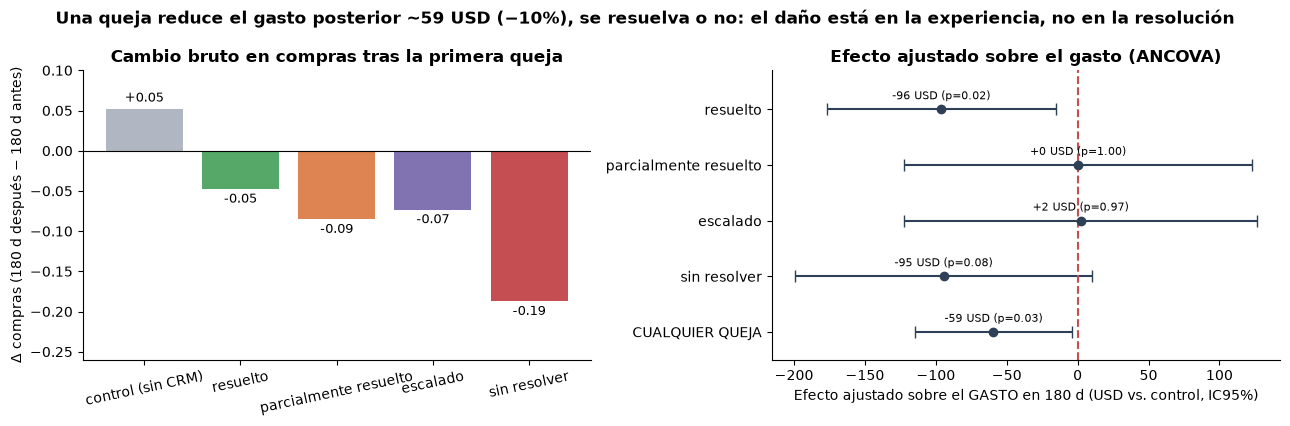

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]; lab = [g.replace('queja_', '').replace('_', ' ').replace('control sin CRM', 'control (sin CRM)') for g in ORDEN_G]
cols_ = ['#B0B7C3', '#55A868', '#DD8452', '#8172B2', '#C44E52']
ax.bar(lab, resumen.delta_compras, color=cols_)
for k_, v in enumerate(resumen.delta_compras): ax.text(k_, v - .005 if v < 0 else v + .005, f'{v:+.2f}', ha='center', va='top' if v < 0 else 'bottom', fontsize=9)
ax.set_ylim(-.26, .1)
ax.axhline(0, color='k', lw=.8); ax.set_ylabel('Δ compras (180 d después − 180 d antes)'); ax.set_title('Cambio bruto en compras tras la primera queja'); ax.tick_params(axis='x', rotation=12)
ax = axes[1]
r_ = pd.concat([res_v.loc[ORDEN_G[1:]], pd.DataFrame({'efecto': [EF_QUEJA], 'IC95_inf': [mq.conf_int().loc['queja', 0]], 'IC95_sup': [mq.conf_int().loc['queja', 1]], 'p_valor': [EF_QUEJA_P]}, index=['CUALQUIER QUEJA'])])
ax.errorbar(r_.efecto, range(len(r_)), xerr=[r_.efecto - r_.IC95_inf, r_.IC95_sup - r_.efecto], fmt='o', color='#2E4057', capsize=4)
ax.axvline(0, color='#C44E52', ls='--'); ax.set_yticks(range(len(r_)), lab[1:] + ['CUALQUIER QUEJA'])
for k_, (v, p) in enumerate(zip(r_.efecto, r_.p_valor)): ax.text(v, k_ - .18, f'{v:+.0f} USD (p={p:.2f})', ha='center', fontsize=8)
ax.set_ylim(len(r_) - .5, -.7)
ax.set_xlabel('Efecto ajustado sobre el GASTO en 180 d (USD vs. control, IC95%)'); ax.set_title('Efecto ajustado sobre el gasto (ANCOVA)')
plt.suptitle(f'Una queja reduce el gasto posterior ~{-EF_QUEJA:.0f} USD (−10%), se resuelva o no: el daño está en la experiencia, no en la resolución', fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a3_crm_quejas.png', dpi=150); plt.show()

**Lectura: ¿las quejas no resueltas reducen la compra? Sí reducen el gasto, pero la falta de resolución no es la causa.**

| Hallazgo | Evidencia |
|---|---|
| A simple vista, "sin resolver" es el peor grupo | Δ compras −0,19 y gasto −26%, frente a +0,05 y +6% del control |
| Pero gran parte es **regresión a la media** | Los clientes con queja compraban más *antes* (1,66 vs. 1,61); al ajustar por compras previas, ningún grupo tiene un efecto significativo sobre el **número de compras** (p ≥ 0,24) |
| Sí hay efecto sobre el **gasto** | Cualquier queja → **−$59 en 180 días vs. control (−10%; IC95 −$114 a −$4; p = 0,035)** |
| **Resolver no lo revierte** | Sin resolver vs. resuelto: +0,002 compras (p = 0,99). Las quejas *resueltas* tienen el mismo efecto sobre el gasto que las no resueltas (−$96 vs. −$95) |
| Probabilidad de no volver a comprar | Sin resolver: OR = 1,36 (p = 0,13). Va en la dirección esperada, pero no es concluyente |
| Robustez | Ventana de 90 días: mismas direcciones, también no significativas |
| Tiempo de respuesta | El cuartil más lento (> 21 h) muestra −0,29 compras en el descriptivo, pero en la regresión el efecto no es significativo (−0,04 compras por cada 24 h; p = 0,47) |

**Interpretación causal:** el diseño de diferencias en diferencias con control y ajuste por historia previa elimina la regresión a la media y las diferencias de segmento. Lo que queda es que **la experiencia negativa que motiva la queja reduce el gasto posterior ~10%**, se resuelva o no el caso. Resolver la queja (tal como hoy se resuelve) **no recupera** al cliente. Por eso la recomendación no es solo "resolver más", sino **prevenir lo que genera la queja** (calidad de producto y errores de pedido, que son a la vez los motivos de devolución) y diseñar una **compensación proactiva** que se pueda medir con un experimento.

*Limitación:* son 176 a 272 clientes por grupo, así que efectos pequeños pueden no detectarse (baja potencia estadística). Que no sea significativo no prueba que no haya efecto.

## 3. Riesgo de churn (fuga de clientes)

### 3.1 Elección de la métrica de inactividad: candidatas y validación
Una métrica de churn solo sirve si **anticipa** quién deja de comprar. Para comprobarlo se hace un *backtest*: se calcula cada métrica con los datos hasta el **2024-06-30** y se mide qué tan bien predice quién **no compra en el segundo semestre de 2024**, usando el AUC (0,5 = azar, 1 = perfecto).

Candidatas:
1. **Recencia** (días desde la última compra): la métrica clásica de RFM.
2. **Ratio de Inactividad (RI)** = recencia / intervalo medio entre compras del propio cliente. Normaliza por el ritmo de cada cliente.
3. **Probabilidad de la brecha**: qué tan improbable es la inactividad observada si el cliente siguiera comprando a su ritmo habitual (modelo de Poisson, p = e^(−λ·recencia)).
4. **Frecuencia histórica** (n.º de compras), como referencia.

In [13]:
CB = pd.Timestamp('2024-06-30')
from sklearn.metrics import roc_auc_score

def rasgos(corte):
    h = ventas[ventas.fecha <= corte].sort_values(['cliente_id', 'fecha']); g = h.groupby('cliente_id')
    f = pd.DataFrame({'compras': g.size(), 'primera': g.fecha.min(), 'ultima': g.fecha.max(),
                      'ventas': g.monto_neto.sum(), 'margen_neto': g.margen_neto.sum()})
    f['segmento'] = f.index.map(seg)
    f['recencia'] = (corte - f.ultima).dt.days
    # Exposición: todos los clientes se observan desde 2023-01-01 (inicio de la data). Opción conservadora: no infla
    # el ritmo de quien aparece tarde (ver supuesto en 3.2).
    dias_obs = pd.Series((corte - INI).days, index=f.index)
    f['lambda_dia'] = f.compras / dias_obs                                    # ritmo de compra observado
    ipi = (f.ultima - f.primera).dt.days / (f.compras - 1).replace(0, np.nan)
    ipi_seg = ipi[f.compras >= 3].groupby(f.segmento).median().reindex(ORDEN_SEG)
    ipi_seg = ipi_seg.fillna(ipi[f.compras.between(2, 3)].median())           # Inactivo: todos con 1 compra
    f['RI'] = f.recencia / pd.Series(np.where(f.compras >= 3, ipi, f.segmento.map(ipi_seg)), index=f.index).clip(lower=7)
    lam_s = f.groupby('segmento').lambda_dia.mean()
    f['p_brecha'] = np.exp(-np.where(f.compras >= 3, f.lambda_dia, f.segmento.map(lam_s)) * f.recencia)
    f['tramo_compras'] = pd.cut(f.compras, [0, 1, 2, 5, 10, 999], labels=['1', '2', '3–5', '6–10', '11+'])
    f['ventas_mes'] = f.ventas / (dias_obs / 30.44)
    f['margen_mes'] = f.margen_neto / (dias_obs / 30.44)
    f['p_pausa_normal'] = np.exp(-f.lambda_dia * 184)          # P(no comprar en 6 meses) si mantiene su ritmo y NO se fuga
    return f

bt = rasgos(CB); bt['no_compra_6m'] = (~bt.index.isin(ventas[ventas.fecha > CB].cliente_id)).astype(int)
auc = pd.Series({'Recencia (días)': roc_auc_score(bt.no_compra_6m, bt.recencia),
                 'Ratio de Inactividad (RI)': roc_auc_score(bt.no_compra_6m, bt.RI),
                 'Probabilidad de la brecha (Poisson)': roc_auc_score(bt.no_compra_6m, -bt.p_brecha),
                 'Frecuencia histórica (−compras)': roc_auc_score(bt.no_compra_6m, -bt.compras)}, name='AUC_backtest')
display(auc.round(3).to_frame())
display(pd.Series({s: roc_auc_score(x.no_compra_6m, x.recencia) for s, x in bt.groupby('segmento') if x.no_compra_6m.nunique() > 1},
                  name='AUC de la recencia DENTRO de cada segmento').round(3).to_frame())
m1 = smf.logit('no_compra_6m ~ np.log(compras) + C(segmento)', data=bt).fit(disp=0)
m2 = smf.logit('no_compra_6m ~ np.log(compras) + C(segmento) + recencia', data=bt).fit(disp=0)
lr = 2 * (m2.llf - m1.llf); print(f'¿La recencia agrega información a la frecuencia? LR = {lr:.2f}, p = {stats.chi2.sf(lr, 1):.3f}')

,AUC_backtest
Recencia (días),0.696
Ratio de Inactividad (RI),0.598
Probabilidad de la brecha (Poisson),0.439
Frecuencia histórica (−compras),0.817


,AUC de la recencia DENTRO de cada segmento
Esporádico,0.438
Frecuente,0.500
Nuevo,0.443
Premium,0.496


¿La recencia agrega información a la frecuencia? LR = 2.20, p = 0.138


C:\Users\edgar\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\edgar\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [14]:
# ¿Por qué la recencia no predice? Prueba de proceso "sin memoria": si los clientes compran a ritmo constante (Poisson),
# los intervalos entre compras tienen coeficiente de variación ≈ 1 y el ritmo no cambia en el tiempo.
vv_ = ventas.sort_values(['cliente_id', 'fecha']).assign(gap=lambda x: x.groupby('cliente_id').fecha.diff().dt.days)
cv = vv_.groupby('segmento').gap.agg(['mean', 'std']).assign(CV=lambda x: x['std'] / x['mean']).loc[['Premium', 'Frecuente', 'Esporádico', 'Nuevo']]
print('Intervalo entre compras (días) por segmento:'); display(cv.round(2))
sem_ = ventas.assign(sem=ventas.fecha.dt.year.astype(str) + '-S' + np.where(ventas.fecha.dt.month <= 6, '1', '2')).groupby(['cliente_id', 'sem']).size().unstack(fill_value=0)
print('Compras promedio por cliente y semestre (ritmo estable = sin desgaste):'); display(sem_.groupby(seg).mean().reindex(ORDEN_SEG).round(2))
cmp = bt.groupby('segmento').agg(clientes=('compras', 'size'), no_compra_observado=('no_compra_6m', 'mean'), no_compra_esperado_sin_fuga=('p_pausa_normal', 'mean')).reindex(ORDEN_SEG)
cmp['exceso_fuga_pp'] = (cmp.no_compra_observado - cmp.no_compra_esperado_sin_fuga) * 100
print('No-compra en 2024-S2: observado vs. esperado si cada cliente mantuviera su ritmo (pausa normal):')
display(cmp.style.format({'no_compra_observado': '{:.1%}', 'no_compra_esperado_sin_fuga': '{:.1%}', 'exceso_fuga_pp': '{:+.1f}'}))

Intervalo entre compras (días) por segmento:


,mean,std,CV
segmento,,,
Premium,37.08,37.83,1.02
Frecuente,62.07,61.25,0.99
Esporádico,172.99,140.25,0.81
Nuevo,249.44,166.81,0.67


Compras promedio por cliente y semestre (ritmo estable = sin desgaste):


sem,2023-S1,2023-S2,2024-S1,2024-S2
segmento,,,,
Premium,4.48,4.66,4.79,4.59
Frecuente,2.62,2.60,2.62,2.68
Esporádico,0.70,0.70,0.72,0.68
Nuevo,0.30,0.34,0.36,0.34
Inactivo,0.25,0.26,0.23,0.26


No-compra en 2024-S2: observado vs. esperado si cada cliente mantuviera su ritmo (pausa normal):


,clientes,no_compra_observado,no_compra_esperado_sin_fuga,exceso_fuga_pp
segmento,,,,
Premium,805,1.2%,2.1%,-0.9
Frecuente,2421,6.8%,10.5%,-3.7
Esporádico,2652,49.0%,49.7%,-0.8
Nuevo,582,83.5%,66.7%,+16.8
Inactivo,652,100.0%,71.4%,+28.6


**Lectura: en RetailVenture la recencia NO es una señal de fuga.**

- La métrica clásica (recencia) tiene un AUC de 0,70, pero **solo porque refleja la frecuencia**. Dentro de cada segmento, su AUC es ≈ 0,5 (azar) o menos, y agregada a la frecuencia **no aporta información** (prueba de razón de verosimilitud, p = 0,14).
- El Ratio de Inactividad (0,60) y la probabilidad de la brecha (0,44) son peores todavía. **Se descartan con evidencia.**
- **Por qué:** los clientes compran con un ritmo **constante y aleatorio** (proceso de Poisson). El coeficiente de variación de los intervalos entre compras es ≈ 1 en Premium (1,02) y Frecuente (0,99), y las compras por semestre son estables en los 4 semestres (Premium 4,5–4,8; Frecuente 2,6–2,7). Que un Premium lleve 90 días sin comprar es una **pausa aleatoria, no un abandono**.
- **Contra la pausa normal esperada:** Premium, Frecuente y Esporádico vuelven a comprar **igual o más** de lo que predice su propio ritmo (exceso ≤ 0). El exceso de inactividad (fuga *real*) aparece solo en **Nuevo (+16,8 pp)** e **Inactivo (+28,6 pp)**, es decir, en clientes de 1–2 compras que no consolidan el hábito.

Este es un hallazgo metodológico importante para la defensa: **una regla del tipo "más de 90 días sin comprar = churn" marcaría como fugados a clientes leales**, y una campaña de retención basada en ella gastaría recursos en clientes que iban a volver igual.

### 3.2 Métrica adoptada: Probabilidad de Inactividad a 6 meses (PI6)
Como el riesgo depende del **ritmo de compra** del cliente y no de su recencia, se define:

> **PI6** = probabilidad empírica de que un cliente **no compre en los próximos 6 meses**, estimada por *segmento × tramo de compras acumuladas*.

**Validación fuera de tiempo:** la tabla de probabilidades se estima con el corte 2023-12-31 (resultado: primer semestre de 2024) y se aplica sin cambios al corte 2024-06-30 para predecir el segundo semestre. Así se evita evaluar la métrica con los mismos datos con los que se construyó.

Clasificación: **Activo** (PI6 < 30%) · **En riesgo** (30–60%) · **Alto riesgo** (PI6 ≥ 60%).

Para no contar como pérdida una pausa normal de compra, se separan dos medidas:
- **Ingreso en riesgo bruto** = PI6 × ingreso esperado a 6 meses al ritmo histórico del cliente. Es una cota superior: incluye pausas que se recuperan solas.
- **Fuga estructural** = exceso de no-compra del **segmento** del cliente (medido en el backtest) sobre la pausa normal esperada por Poisson, × ingreso esperado a 6 meses. Se mide por segmento porque, dentro de un segmento, las diferencias de frecuencia entre clientes son en buena parte rachas aleatorias que se revierten (regresión a la media). Es solo la inactividad *en exceso* de lo que explica el ritmo del cliente: la pérdida que realmente ocurre.

**Supuesto de exposición:** el ritmo de compra λ de cada cliente se mide sobre toda la ventana observada (desde 2023-01-01). El 76% de los clientes compraba antes de su fecha de registro (A1), así que la mayoría ya existía al inicio de la data. Medir desde la primera compra inflaría el ritmo de los clientes que aparecen tarde, y con eso la fuga estimada. Es la opción **conservadora**.

In [15]:
def tabla_pi6(f): return f.groupby(['segmento', 'tramo_compras'], observed=True).no_compra_6m.mean()
def aplicar_pi6(f, tabla, respaldo):
    pi = pd.Series([tabla.get((s, tr), np.nan) for s, tr in zip(f.segmento, f.tramo_compras)], index=f.index)
    return pi.fillna(f.segmento.map(respaldo))

c1 = pd.Timestamp('2023-12-31'); f1 = rasgos(c1)
f1['no_compra_6m'] = (~f1.index.isin(ventas[(ventas.fecha > c1) & (ventas.fecha <= c1 + pd.Timedelta(days=182))].cliente_id)).astype(int)
bt['PI6'] = aplicar_pi6(bt, tabla_pi6(f1), f1.groupby('segmento').no_compra_6m.mean())
print(f"AUC fuera de tiempo de PI6 (tabla 2023-12 → resultado 2024-S2): {roc_auc_score(bt.no_compra_6m, bt.PI6):.3f}")
bt['estado'] = pd.cut(bt.PI6, [-.01, .30, .60, 1.01], labels=['Activo', 'En riesgo', 'Alto riesgo'], right=False)
cal = bt.groupby('estado', observed=True).agg(clientes=('PI6', 'size'), PI6_predicho=('PI6', 'mean'), no_compra_real=('no_compra_6m', 'mean'))
print('Calibración del backtest:'); display(cal.style.format({'PI6_predicho': '{:.1%}', 'no_compra_real': '{:.1%}'}))

AUC fuera de tiempo de PI6 (tabla 2023-12 → resultado 2024-S2): 0.891
Calibración del backtest:


,clientes,PI6_predicho,no_compra_real
estado,,,
Activo,3226,5.1%,5.4%
En riesgo,1703,49.8%,40.7%
Alto riesgo,2183,81.8%,79.9%


In [16]:
# --- Estado actual (corte 2024-12-31), con la tabla estimada en el backtest más reciente ---
hoy = rasgos(CORTE)
hoy['PI6'] = aplicar_pi6(hoy, tabla_pi6(bt), bt.groupby('segmento').no_compra_6m.mean())
hoy['estado'] = pd.cut(hoy.PI6, [-.01, .30, .60, 1.01], labels=['Activo', 'En riesgo', 'Alto riesgo'], right=False)
hoy['ingreso_6m_esperado'] = hoy.ventas_mes * 6
# Exceso de no-compra sobre la pausa normal, estimado por SEGMENTO en el backtest (tabla `cmp` de 3.1).
# No se calcula por cliente ni por tramo de compras: un Esporádico con muchas compras tuvo una racha alta y luego vuelve al
# ritmo de su segmento (regresión a la media), lo que no es fuga. El segmento refleja el ritmo "verdadero" del cliente.
exc = (cmp.exceso_fuga_pp / 100).clip(lower=0)
print('Exceso de no-compra usado como fuga estructural (pp):', (exc * 100).round(1).to_dict())
hoy['exceso'] = hoy.segmento.map(exc).fillna(0)
hoy['ingreso_en_riesgo_bruto'] = hoy.PI6 * hoy.ingreso_6m_esperado
hoy['fuga_estructural_6m'] = hoy.exceso * hoy.ingreso_6m_esperado
hoy['margen_fuga_estructural_6m'] = hoy.exceso * hoy.margen_mes * 6

var = hoy.groupby('segmento').agg(clientes=('PI6', 'size'), en_riesgo=('estado', lambda s: (s != 'Activo').sum()),
                                  alto_riesgo=('estado', lambda s: (s == 'Alto riesgo').sum()), PI6_media=('PI6', 'mean'),
                                  ingreso_en_riesgo_bruto_6m=('ingreso_en_riesgo_bruto', 'sum'), fuga_estructural_6m=('fuga_estructural_6m', 'sum'),
                                  margen_fuga_estructural_6m=('margen_fuga_estructural_6m', 'sum')).reindex(ORDEN_SEG)
var['%_fuga_estructural'] = var.fuga_estructural_6m / var.fuga_estructural_6m.sum() * 100
var.loc['TOTAL'] = var.sum(numeric_only=True); var.loc['TOTAL', 'PI6_media'] = hoy.PI6.mean()
var.to_csv(TAB / 'a3_churn_valor_en_riesgo.csv')
var.style.format({'PI6_media': '{:.1%}', 'ingreso_en_riesgo_bruto_6m': '${:,.0f}', 'fuga_estructural_6m': '${:,.0f}', 'margen_fuga_estructural_6m': '${:,.0f}',
                  '%_fuga_estructural': '{:.1f}%', 'clientes': '{:,.0f}', 'en_riesgo': '{:,.0f}', 'alto_riesgo': '{:,.0f}'})

Exceso de no-compra usado como fuga estructural (pp):

 {'Premium': 0.0, 'Frecuente': 0.0, 'Esporádico': 0.0, 'Nuevo': 16.8, 'Inactivo': 28.6}


,clientes,en_riesgo,alto_riesgo,PI6_media,ingreso_en_riesgo_bruto_6m,fuga_estructural_6m,margen_fuga_estructural_6m,%_fuga_estructural
segmento,,,,,,,,
Premium,805,0,0,1.0%,"$12,663",$0,$0,0.0%
Frecuente,"2,422",0,0,7.1%,"$159,120",$0,$0,0.0%
Esporádico,"2,784","2,784","1,685",55.1%,"$398,705",$0,$0,0.0%
Nuevo,716,716,716,85.4%,"$72,816","$13,769","$2,758",37.7%
Inactivo,881,881,881,100.0%,"$79,383","$22,710","$3,522",62.3%
TOTAL,"7,608","4,381","3,282",42.2%,"$722,687","$36,480","$6,280",100.0%


In [17]:
# Flujo de clientes 2023 → 2024: ingreso que se fue con los clientes que dejaron de comprar y cuánto se repuso
a = ventas.groupby(['cliente_id', ventas.fecha.dt.year.rename('anio')]).monto_neto.agg(['size', 'sum']).unstack(fill_value=0)
a.columns = ['n23', 'n24', 'v23', 'v24']; a['segmento'] = a.index.map(seg)
flujo = pd.DataFrame({
    'clientes_perdidos': a[(a.n23 > 0) & (a.n24 == 0)].groupby('segmento').size(),
    'ingreso_2023_perdidos': a[(a.n23 > 0) & (a.n24 == 0)].groupby('segmento').v23.sum(),
    'clientes_nuevos_2024': a[(a.n23 == 0) & (a.n24 > 0)].groupby('segmento').size(),
    'ingreso_2024_nuevos': a[(a.n23 == 0) & (a.n24 > 0)].groupby('segmento').v24.sum()}).reindex(ORDEN_SEG).fillna(0)
flujo.loc['TOTAL'] = flujo.sum()
display(flujo.style.format('{:,.0f}'))
pc_ = ventas.groupby('cliente_id').agg(primera=('fecha', 'min'), compras=('fecha', 'size'))
pc_ = pc_[pc_.primera <= CB]; pc_['segmento'] = pc_.index.map(seg)
print('% de clientes (primera compra ≤ 2024-06) que NUNCA hicieron una segunda compra:')
print((pc_.groupby('segmento').compras.apply(lambda s: (s == 1).mean()) * 100).reindex(ORDEN_SEG).round(1).to_dict())

,clientes_perdidos,ingreso_2023_perdidos,clientes_nuevos_2024,ingreso_2024_nuevos
segmento,,,,
Premium,0,0,0,0
Frecuente,17,"34,020",15,"32,736"
Esporádico,503,"332,676",530,"418,163"
Nuevo,278,"107,525",307,"119,922"
Inactivo,446,"167,257",435,"150,030"
TOTAL,"1,244","641,478","1,287","720,851"


% de clientes (primera compra ≤ 2024-06) que NUNCA hicieron una segunda compra:
{'Premium': 0.0, 'Frecuente': 0.1, 'Esporádico': 9.3, 'Nuevo': 61.2, 'Inactivo': 100.0}


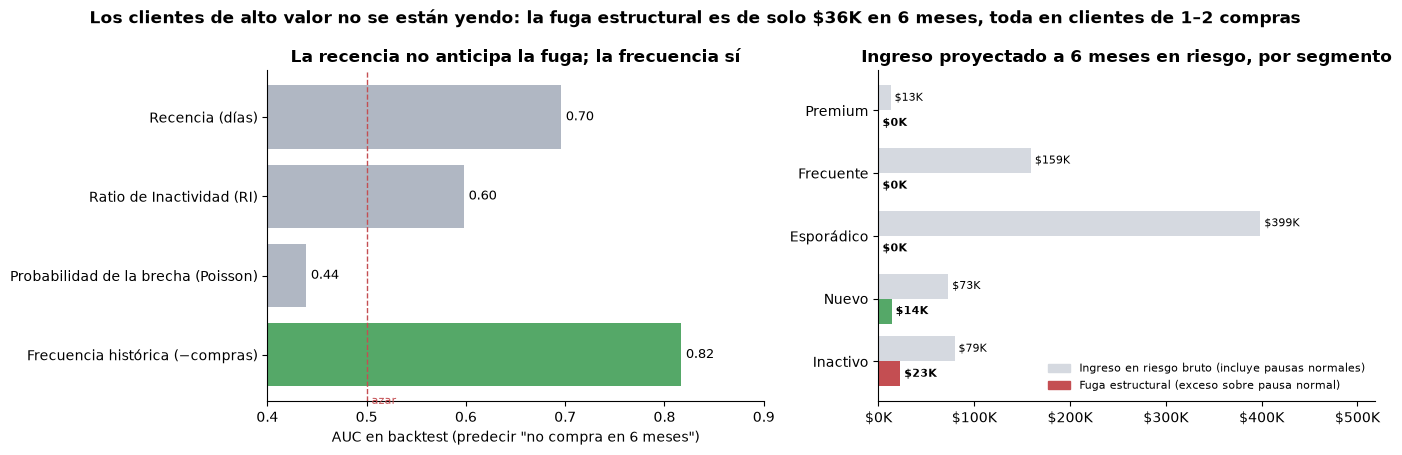

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
ax.barh(auc.index[::-1], auc.values[::-1], color=['#55A868' if 'Frecuencia' in i else '#B0B7C3' for i in auc.index[::-1]])
for k_, v in enumerate(auc.values[::-1]): ax.text(v + .005, k_, f'{v:.2f}', va='center', fontsize=9)
ax.axvline(.5, color='#C44E52', ls='--', lw=1); ax.text(.505, -.62, 'azar', color='#C44E52', fontsize=8)
ax.set_xlim(.4, .9); ax.set_xlabel('AUC en backtest (predecir "no compra en 6 meses")'); ax.set_title('La recencia no anticipa la fuga; la frecuencia sí')
ax = axes[1]; vv = var.drop('TOTAL')
y = np.arange(len(vv))
ax.barh(y - .2, vv.ingreso_en_riesgo_bruto_6m, .4, color='#D5D9E0', label='Ingreso en riesgo bruto (incluye pausas normales)')
ax.barh(y + .2, vv.fuga_estructural_6m, .4, color=[PALETA[s] for s in vv.index], label='Fuga estructural (exceso sobre pausa normal)')
for k_, (b_, e_) in enumerate(zip(vv.ingreso_en_riesgo_bruto_6m, vv.fuga_estructural_6m)):
    ax.text(b_, k_ - .2, f' ${b_/1e3:,.0f}K', va='center', fontsize=8); ax.text(e_, k_ + .2, f' ${e_/1e3:,.0f}K', va='center', fontsize=8, fontweight='bold')
ax.set_yticks(y, vv.index); ax.invert_yaxis()
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#D5D9E0', label='Ingreso en riesgo bruto (incluye pausas normales)'), Patch(color='#C44E52', label='Fuga estructural (exceso sobre pausa normal)')], frameon=False, fontsize=8, loc='lower right')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K')); ax.set_xlim(0, vv.ingreso_en_riesgo_bruto_6m.max() * 1.3)
ax.set_title('Ingreso proyectado a 6 meses en riesgo, por segmento')
top_seg = vv.fuga_estructural_6m.idxmax()
plt.suptitle(f"Los clientes de alto valor no se están yendo: la fuga estructural es de solo ${var.loc['TOTAL', 'fuga_estructural_6m']/1e3:,.0f}K en 6 meses, toda en clientes de 1–2 compras", fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a3_churn.png', dpi=150); plt.show()

**Lectura**

**La métrica PI6 funciona:** su AUC fuera de tiempo es **0,89**, y está bien calibrada en los grupos activo (5,1% predicho vs. 5,4% real) y alto riesgo (81,8% vs. 79,9%). En el grupo "en riesgo" sobreestima un poco (49,8% vs. 40,7%), lo que la hace conservadora.

**Estado al 2024-12-31:** 4.381 clientes en riesgo o alto riesgo (2.784 Esporádicos, 716 Nuevos y 881 Inactivos). Ningún Premium ni Frecuente está en riesgo.

**¿Cuál es el segmento de mayor valor en riesgo?**
- Por **exposición**: **Esporádico**, con $399K (el 55%) de los $723K de ingreso en riesgo bruto a 6 meses, y 2.784 clientes con una probabilidad media de no comprar del 55%. Pero su inactividad es la **esperable por su ritmo de compra**: el 49% no compra en un semestre cualquiera, y aun así el segmento se repone (503 clientes se fueron en 2023 y llegaron 530 en 2024, con más ingreso).
- Por **fuga real (estructural)**: solo **$36K en 6 meses** (0,8% de las ventas), concentrados en Inactivo (62%) y Nuevo (38%). El 61% de los Nuevos **nunca hace una segunda compra**.

**Flujo de clientes 2023 → 2024:** se fueron 1.244 clientes que habían generado $641K, y llegaron 1.287 que generaron $721K. El ingreso se sostiene **reemplazando clientes de baja frecuencia**, y eso es caro en adquisición. A esto se suma la caída de la recompra de las cohortes nuevas que se vio en A2 (de 23% a 15%).

**Conclusión:** el churn **no es la fuga principal**. El riesgo está en no lograr que los clientes nuevos y esporádicos **pasen a una segunda compra y suban de frecuencia**. Es una palanca de *crecimiento* (convertir Esporádicos en Frecuentes multiplica el CLV de $236 a $840), más que de *retención*.

## 4. Impacto económico consolidado de las fugas (proyección a 6 meses)

Se proyectan los próximos 6 meses (enero a junio de 2025) suponiendo que **nada cambia** (*business as usual*). Esto se justifica porque A2 mostró que las ventas, las devoluciones y los descuentos son estables, sin tendencia ni estacionalidad, así que el promedio mensual de 2024 × 6 es una proyección razonable.

| Fuga | Cómo se calcula | Qué parte es "evitable" |
|---|---|---|
| Devoluciones | Margen perdido mensual × 6 | El exceso de Electrónica y Ropa sobre la tasa del resto de categorías (~10%) |
| Churn | Fuga estructural: exceso de inactividad sobre la pausa normal × ingreso esperado (sección 3) | Lo recuperable con programas de segunda compra y reactivación (se estima en A5) |
| Quejas sin resolver | Efecto estimado en la sección 2 × quejas sin resolver esperadas | Solo si el efecto es significativo |
| Descuentos sin retorno | Descuento mensual × 6 (A2: no generan volumen) | La parte por encima de la política de tienda en online |

Hay **solapamiento**: un cliente en riesgo puede tener también devoluciones. Por eso los componentes se presentan por separado y el total se toma como **cota superior**.

In [19]:
v24 = ventas[ventas.fecha.dt.year == 2024]
mes = lambda s: s / 12 * 6     # promedio mensual 2024 × 6

# (a) Devoluciones
dev_6m = mes(v24.monto_devuelto.sum()); dev_margen_6m = mes((v24.margen_bruto - v24.margen_neto).sum())
resto = v24[~v24.categoria.isin(['Electrónica', 'Ropa_y_Calzado'])].flag_devuelta.mean()
exceso = 0
for c_ in ['Electrónica', 'Ropa_y_Calzado']:
    s = v24[v24.categoria == c_]
    perdida_por_dev = (s.margen_bruto - s.margen_neto).sum() / max(s.flag_devuelta.sum(), 1)       # margen perdido promedio por devolución
    exceso += (s.flag_devuelta.mean() - resto) * len(s) * perdida_por_dev
exceso_6m = mes(exceso)

# (b) Churn
churn_v, churn_m = var.loc['TOTAL', 'fuga_estructural_6m'], var.loc['TOTAL', 'margen_fuga_estructural_6m']

# (c) Quejas: efecto agrupado de tener una queja sobre el gasto en 180 d (≈ 6 meses). La resolución no cambia el efecto (sección 2).
#     Solo se contabiliza como fuga si es significativo; se aplica a los clientes con primera queja esperados en 6 meses.
quejas_6m = mes(crm[(crm.tipo == 'queja') & (crm.fecha.dt.year == 2024)].cliente_id.nunique())
quejas_v_puntual = -EF_QUEJA * quejas_6m
quejas_v = quejas_v_puntual if (EF_QUEJA_P < .05 and EF_QUEJA < 0) else 0.0

# (d) Descuentos sin retorno
desc_6m = mes(v24.descuento_monto.sum())
on = v24[v24.canal == 'online']; tasa_tienda = v24[v24.canal == 'tienda_fisica'].descuento_monto.sum() / v24[v24.canal == 'tienda_fisica'].ingreso_bruto.sum()
desc_online_exceso_6m = mes(on.descuento_monto.sum() - tasa_tienda * on.ingreso_bruto.sum())

ventas_6m = mes(v24.monto_neto.sum()); margen_6m = mes(v24.margen_neto.sum())
imp = pd.DataFrame([
    ('Devoluciones', 'Ingreso reembolsado', dev_6m, dev_margen_6m, exceso_6m),
    ('Churn (fuga estructural)', 'Ingreso no realizado', churn_v, churn_m, np.nan),
    ('Quejas de clientes (insatisfacción)', 'Gasto que se deja de hacer', quejas_v_puntual, quejas_v_puntual * margen_6m / ventas_6m, np.nan),
    ('Descuentos sin retorno en volumen', 'Ingreso cedido', desc_6m, desc_6m, desc_online_exceso_6m),
], columns=['fuga', 'naturaleza', 'ingreso_afectado_6m', 'margen_perdido_6m', 'evitable_identificado_6m']).set_index('fuga')
imp['%_ventas_6m'] = imp.ingreso_afectado_6m / ventas_6m * 100
imp.to_csv(TAB / 'a3_impacto_fugas_6m.csv')
print(f"Exposición bruta por churn (cota superior, incluye pausas normales): ${var.loc['TOTAL', 'ingreso_en_riesgo_bruto_6m']:,.0f}")
print(f"Referencia: ventas proyectadas a 6 meses ${ventas_6m:,.0f} | margen neto proyectado ${margen_6m:,.0f}")
print(f"Efecto de una queja sobre el gasto a 6 meses: {EF_QUEJA:+.1f} USD/cliente (p = {EF_QUEJA_P:.3f}) → "
      f"{'se contabiliza como fuga' if quejas_v else 'NO se contabiliza como fuga cierta (no significativo)'}; clientes con queja esperados en 6 meses: {quejas_6m:,.0f}")
imp.style.format({'ingreso_afectado_6m': '${:,.0f}', 'margen_perdido_6m': '${:,.0f}', 'evitable_identificado_6m': '${:,.0f}', '%_ventas_6m': '{:.1f}%'}, na_rep='—')

Exposición bruta por churn (cota superior, incluye pausas normales): $722,687
Referencia: ventas proyectadas a 6 meses $4,342,290 | margen neto proyectado $781,042
Efecto de una queja sobre el gasto a 6 meses: -59.3 USD/cliente (p = 0.035) → se contabiliza como fuga; clientes con queja esperados en 6 meses: 432


,naturaleza,ingreso_afectado_6m,margen_perdido_6m,evitable_identificado_6m,%_ventas_6m
fuga,,,,,
Devoluciones,Ingreso reembolsado,"$645,361","$300,340","$80,824",14.9%
Churn (fuga estructural),Ingreso no realizado,"$36,480","$6,280",—,0.8%
Quejas de clientes (insatisfacción),Gasto que se deja de hacer,"$25,604","$4,605",—,0.6%
Descuentos sin retorno en volumen,Ingreso cedido,"$242,500","$242,500","$72,312",5.6%


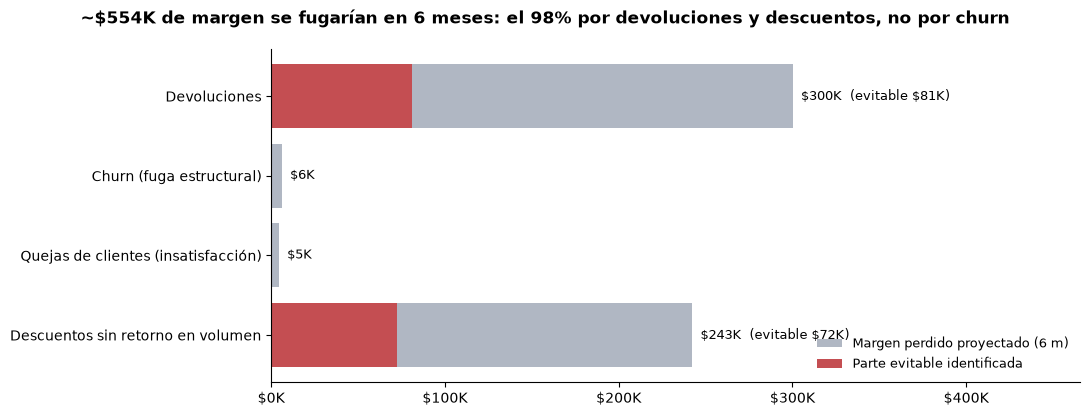

In [20]:
fig, ax = plt.subplots(figsize=(11, 4.2))
plot = imp[['margen_perdido_6m', 'evitable_identificado_6m']].fillna(0).copy()
y = np.arange(len(plot))
ax.barh(y, plot.margen_perdido_6m, color='#B0B7C3', label='Margen perdido proyectado (6 m)')
ax.barh(y, plot.evitable_identificado_6m, color='#C44E52', label='Parte evitable identificada')
for k_, (a, b) in enumerate(zip(plot.margen_perdido_6m, plot.evitable_identificado_6m)):
    ax.text(a, k_, f'  ${a/1e3:,.0f}K' + (f'  (evitable ${b/1e3:,.0f}K)' if b else ''), va='center', fontsize=9)
ax.set_yticks(y, plot.index); ax.invert_yaxis(); ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
ax.set_xlim(0, plot.margen_perdido_6m.max() * 1.55); ax.legend(frameon=False, loc='lower right', fontsize=9)
_dd = plot.loc[['Devoluciones', 'Descuentos sin retorno en volumen'], 'margen_perdido_6m'].sum() / plot.margen_perdido_6m.sum()
fig.suptitle(f"~${plot.margen_perdido_6m.sum()/1e3:,.0f}K de margen se fugarían en 6 meses: el {_dd:.0%} por devoluciones y descuentos, no por churn", fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a3_impacto_fugas.png', dpi=150); plt.show()

**Lectura: la fuga de ingresos está en las devoluciones y los descuentos, no en los clientes que se van.**

Proyección a 6 meses (enero a junio de 2025, si nada cambia), sobre un margen neto esperado de **$781K**:

| Fuga | Margen perdido en 6 m | Parte evitable identificada | Fuente |
|---|---|---|---|
| Devoluciones | **$300K** (reembolsos: $645K, 14,9% de las ventas) | **$81K**: exceso de Electrónica y Ropa sobre la tasa del resto (~10%) | Sección 1 |
| Descuentos sin retorno | **$243K** | **$72K**: igualar el descuento online al de la tienda | A2, sección 4 |
| Quejas (insatisfacción) | $5K (gasto: $26K) | — | Sección 2 |
| Churn estructural | $6K (ingreso: $36K) | — | Sección 3 |
| **Total** | **≈ $554K, el 71% del margen neto proyectado** | **≈ $153K identificados** | |

- El **98% de la fuga de margen** viene de **devoluciones y descuentos**: dos políticas internas que la empresa controla directamente.
- El churn y las quejas son fugas menores en el horizonte de 6 meses. Su valor está en el largo plazo (CLV) y en la *adquisición*.
- **Cautela:** los componentes se solapan (un cliente puede devolver y quejarse), y la parte "evitable" es solo la que ya está identificada con un mecanismo concreto. El potencial total puede ser mayor, y en A5 se va a cuantificar cada recomendación con supuestos explícitos.

## Resumen ejecutivo de A3

1. **Devoluciones (13,4%, estable desde 2023):** las determina **la categoría**. Ropa (21,8%) y Electrónica (17,7%) duplican al resto (~10%), y ningún producto es anómalo dentro de su categoría. Canal, segmento y descuento no influyen. Electrónica genera el 55% del monto devuelto. **No hay devolvedores seriales**: la distribución de devoluciones por cliente coincide con la que daría el azar.
2. **CRM:** una queja reduce el gasto posterior ~**$59 (−10%) en 6 meses** (p = 0,035), **se resuelva o no**. La resolución actual no recupera al cliente; hay que prevenir la causa (calidad y errores de pedido).
3. **Churn:** la recencia **no** predice la fuga, porque los clientes compran a un ritmo constante y aleatorio. Se adopta la métrica **PI6** (AUC fuera de tiempo de 0,89). Premium y Frecuente **no están en riesgo**. El mayor valor *expuesto* es Esporádico ($399K), pero la fuga *real* es solo de **$36K** en clientes de 1–2 compras. El problema es de *activación* (61% de los Nuevos no repite), no de *retención*.
4. **Impacto a 6 meses:** ≈ **$554K de margen se pierden** (71% del margen neto proyectado), y el 98% se debe a **devoluciones ($300K) y descuentos ($243K)**. Ya hay **$153K evitables identificados**.

→ **Para A4 (marketing):** revisar si las campañas con descuento repiten el patrón de "descuento sin volumen" y por qué los clientes con quejas o devoluciones convierten menos.